# Étude de cas 3 : Télésurveillance cardiaque : Jalon 2
## Apprendre sur le signal brut (chapitre 2 : CNN 1D et auto-encodeurs)

M2 SDIA, Advanced Artificial Intelligence, ENSET, 2026-2027.

**Ce que fait ce notebook** (dans l'ordre du sujet) :
0. mise en place, données, graine, découpage par patient ;
1. comparateur : MLP sur descripteurs RR (réimplémenté ici, voir la note ci-dessous) ;
2. vérification théorique du champ réceptif (à la main + code) ;
3. CNN 1D sur signal brut : ablations profondeur / noyau / agrégation / dilatation, normalisation ;
4. comparaison des deux appareils et calibration du bruit « de type patch » ;
5. auto-encodeurs débruiteurs (V1 convolutif, V2 U-Net) ;
6. effet du débruitage sur la classification du patch (validation) ;
7. choix du modèle, contraintes d'embarquement, **évaluation finale sur le test (une seule fois)** ;
8. **page de décisions** (dernière cellule du notebook).

**Protocole.** Tous les réglages se font sur la validation ; le test n'est utilisé que dans la dernière section.

**Note importante.** Le notebook de démarrage `uc3_demarrage.ipynb` (métriques cliniques, `poids`, MLP de référence, `journaliser`) n'était pas disponible lors de la rédaction. Ces éléments sont donc **réimplémentés** ci-dessous avec la même intention. Si votre version diffère (signature de `journaliser`, définition des métriques cliniques, MLP du jalon 1), remplacez les cellules correspondantes : le reste du notebook n'en dépend que par `poids`, `metriques` et `journaliser`.

**Version corrigée.** Les cellules de texte ont été harmonisées avec la page de décisions : valeur du champ réceptif des dilatations (526 éch. = 4,2 s, comme mesuré par le code), nuance sur le lien F1 / champ réceptif, justification du choix d'architecture au regard de la contrainte d'embarquement, définition de la mesure d'amplitude R. Aucune cellule de code ni aucun résultat n'a été modifié.

In [1]:
import os, sys, time, json, platform, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy, sklearn, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from scipy.signal import butter, sosfiltfilt, find_peaks, welch
from sklearn.metrics import f1_score, recall_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler

SEED = 0
# UC3_RAPIDE=1 : mode « test de fumée » (peu de données, 1 époque) ; ne sert qu'à vérifier que le code tourne.
RAPIDE = os.environ.get("UC3_RAPIDE", "0") == "1"

def fixer_graines(s=SEED):
    np.random.seed(s); tf.keras.utils.set_random_seed(s)
fixer_graines()

print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| tensorflow", tf.__version__, "| pandas", pd.__version__)
print("Mode rapide (test de fumée) :", RAPIDE)

for d in [os.environ.get("UC3_DATA", ""), "/content/data", "./data", "/mnt/user-data/uploads", "."]:
    if d and os.path.exists(os.path.join(d, "uc3_holterA.npz")):
        DATA_DIR = d; break
else:
    raise FileNotFoundError("uc3_holterA.npz introuvable : placez les .npz dans data/ (ou /content/data sur Colab).")
print("Données lues dans :", DATA_DIR)

RES = {}          # tous les résultats chiffrés, écrits dans resultats_jalon2.json
def sauver():
    with open("resultats_jalon2.json", "w") as f:
        json.dump(RES, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
os.makedirs("modeles", exist_ok=True)

I0000 00:00:1792139564.729713     101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792139565.606957     101 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.3 | numpy 2.4.4 | scipy 1.17.1 | sklearn 1.8.0 | tensorflow 2.21.0 | pandas 3.0.2
Mode rapide (test de fumée) : False
Données lues dans : /mnt/user-data/uploads


## 0. Données, découpage par patient, pondération des classes

In [2]:
FS, N = 125, 1250
NOMS = ["sinusal", "FA", "ESV", "tachy sin.", "bloc AV"]

dA, dB = np.load(f"{DATA_DIR}/uc3_holterA.npz"), np.load(f"{DATA_DIR}/uc3_patchB.npz")
A = {k: dA[k] for k in dA.files}
B = {k: dB[k] for k in dB.files}

# découpage imposé par patient : aucun patient ne doit apparaître dans deux ensembles
for nom, D in [("Holter A", A), ("Patch B", B)]:
    ens = {s: set(D["patient_" + s].tolist()) for s in ["train", "val", "test"]}
    assert not (ens["train"] & ens["val"]) and not (ens["train"] & ens["test"]) and not (ens["val"] & ens["test"]), nom
    print(nom, {s: (D["X_" + s].shape[0], len(ens[s])) for s in ens}, "(fenêtres, patients)")

if RAPIDE:   # sous-échantillonnage pour le test de fumée
    for s, pas in [("train", 14), ("val", 6)]:
        for k in [k for k in A if k.endswith("_" + s)]: A[k] = A[k][::pas]
    for s in ["train", "val"]:
        for k in [k for k in B if k.endswith("_" + s)]: B[k] = B[k][::3]

# pondération des classes (équivalent de « poids » de la section 3 : n / (K * n_k))
cw = compute_class_weight("balanced", classes=np.arange(5), y=A["classe_train"])
poids = {c: float(w) for c, w in enumerate(cw)}
print("poids :", {NOMS[c]: round(w, 2) for c, w in poids.items()})

# signal brut normalisé par fenêtre (moyenne nulle, écart-type unité) : (N, 1250, 1)
def normaliser_fenetres(X):
    X = X.astype("float32")
    mu, sd = X.mean(axis=1, keepdims=True), X.std(axis=1, keepdims=True)
    return ((X - mu) / (sd + 1e-6))[..., None]

SA = {s: normaliser_fenetres(A["X_" + s]) for s in ["train", "val", "test"]}
SB = {s: normaliser_fenetres(B["X_" + s]) for s in ["train", "val", "test"]}
XA = {s: A["X_" + s].astype("float32") for s in ["train", "val", "test"]}   # en mV
XB = {s: B["X_" + s].astype("float32") for s in ["train", "val", "test"]}
temps = np.arange(N) / FS
print({k: v.shape for k, v in SA.items()}, {k: v.shape for k, v in SB.items()})

Holter A {'train': (8400, 280), 'val': (1800, 60), 'test': (1800, 60)} (fenêtres, patients)
Patch B {'train': (300, 12), 'val': (150, 6), 'test': (1050, 42)} (fenêtres, patients)
poids : {'sinusal': 0.39, 'FA': 1.39, 'ESV': 1.65, 'tachy sin.': 1.69, 'bloc AV': 2.02}
{'train': (8400, 1250, 1), 'val': (1800, 1250, 1), 'test': (1800, 1250, 1)} {'train': (300, 1250, 1), 'val': (150, 1250, 1), 'test': (1050, 1250, 1)}


## Outils : journal d'expériences et métriques

In [ ]:
JOURNAL = "journal_experiences.csv"
if os.path.exists(JOURNAL): os.remove(JOURNAL)    # le journal est reconstruit à chaque exécution complète

def journaliser(jalon, essai, config, metriques, remarque=""):
    # Réimplémentation minimale : à remplacer par la fonction du notebook de démarrage si sa signature diffère.
    ligne = {"horodatage": time.strftime("%Y-%m-%d %H:%M:%S"), "jalon": jalon, "essai": essai,
             "config": json.dumps(config, default=str), "metriques": json.dumps(metriques, default=lambda o: float(o)),
             "remarque": remarque}
    pd.DataFrame([ligne]).to_csv(JOURNAL, mode="a", header=not os.path.exists(JOURNAL), index=False)

def metriques(y, p):
    y, p = np.asarray(y), np.asarray(p)
    labs = list(range(5))
    alerte, arythmie = p != 0, y != 0       # alerte = tout rythme prédit autre que sinusal
    return {"f1_macro": float(f1_score(y, p, average="macro", labels=labs, zero_division=0)),
            "f1_classes": f1_score(y, p, average=None, labels=labs, zero_division=0).round(3).tolist(),
            "rappel_classes": recall_score(y, p, average=None, labels=labs, zero_division=0).round(3).tolist(),
            "sensibilite_alerte": float(alerte[arythmie].mean()),
            "fausses_alertes": float(alerte[~arythmie].mean())}

def ic_bootstrap(y, p, pat, B_=500, seed=0):
    # IC 95 % de la F1 macro par bootstrap SUR LES PATIENTS (les fenêtres d'un patient ne sont pas indépendantes)
    y, p, pat = np.asarray(y), np.asarray(p), np.asarray(pat)
    rng = np.random.default_rng(seed)
    idx = {u: np.where(pat == u)[0] for u in np.unique(pat)}
    cles = np.array(list(idx))
    vals = []
    for _ in range(B_):
        sel = np.concatenate([idx[u] for u in rng.choice(cles, len(cles))])
        vals.append(f1_score(y[sel], p[sel], average="macro", labels=np.unique(y[sel]), zero_division=0))
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

## 1. Comparateur : MLP sur descripteurs RR

Détection des pics R (filtre passe-bande 5-20 Hz, énergie lissée, seuil adaptatif), puis 13 descripteurs de variabilité du rythme et d'amplitude des QRS. MLP 64-32 avec la même pondération de classes. **C'est une réimplémentation** du comparateur du jalon 1 / de la section 3 ; elle sert de point de repère pour le CNN.

In [4]:
SOS_QRS = butter(2, [5, 20], btype="band", fs=FS, output="sos")
NOMS_DESC = ["n_batt", "rr_moy", "rr_sd", "rmssd", "pnn50", "rr_cv", "rr_min", "rr_max", "rr_max/med",
             "frac_courts", "frac_longs", "amp_cv", "amp_max/med"]

def detecter_R(x):
    y = sosfiltfilt(SOS_QRS, x.astype("float64"))
    env = np.convolve(y ** 2, np.ones(10) / 10, mode="same")
    pk, _ = find_peaks(env, height=0.3 * np.percentile(env, 99), distance=int(0.25 * FS))
    pk = np.array([max(range(max(p - 5, 0), min(p + 6, N)), key=lambda i: abs(y[i])) for p in pk], dtype=int)
    return pk, y

def descripteurs_fenetre(x):
    pk, y = detecter_R(x)
    if len(pk) < 3: return [len(pk)] + [np.nan] * 12
    rr = np.diff(pk) / FS; amp = np.abs(y[pk]); med = np.median(rr)
    return [len(pk), rr.mean(), rr.std(), np.sqrt(np.mean(np.diff(rr) ** 2)), np.mean(np.abs(np.diff(rr)) > 0.05),
            rr.std() / rr.mean(), rr.min(), rr.max(), rr.max() / med, np.mean(rr < 0.85 * med),
            np.mean(rr > 1.15 * med), amp.std() / amp.mean(), amp.max() / np.median(amp)]

def descripteurs(X): return np.array([descripteurs_fenetre(x) for x in X], dtype="float64")

t0 = time.time()
DA = {s: descripteurs(XA[s]) for s in ["train", "val"]}
DB = {s: descripteurs(XB[s]) for s in ["train", "val"]}
print(f"descripteurs calculés en {time.time()-t0:.0f} s ; fenêtres sans 3 pics détectés :",
      {"Holter val": int(np.isnan(DA['val'][:, 1]).sum()), "patch val": int(np.isnan(DB['val'][:, 1]).sum())})

med = np.nanmedian(DA["train"], axis=0)
def prep(D): return np.where(np.isnan(D), med, D)
sc = StandardScaler().fit(prep(DA["train"]))
FA_ = {s: sc.transform(prep(DA[s])).astype("float32") for s in DA}
FB_ = {s: sc.transform(prep(DB[s])).astype("float32") for s in DB}

fixer_graines()
mlp = keras.Sequential([layers.Input((13,)), layers.Dense(64, activation="relu"), layers.Dense(32, activation="relu"),
                        layers.Dense(5, activation="softmax")])
mlp.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
mlp.fit(FA_["train"], A["classe_train"], validation_data=(FA_["val"], A["classe_val"]), class_weight=poids,
        epochs=3 if RAPIDE else 100, batch_size=128, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
p_mlp_A = mlp.predict(FA_["val"], verbose=0).argmax(1)
p_mlp_B = mlp.predict(FB_["val"], verbose=0).argmax(1)
m_mlp_A, m_mlp_B = metriques(A["classe_val"], p_mlp_A), metriques(B["classe_val"], p_mlp_B)
print("MLP descripteurs | Holter val F1 macro = %.3f | patch val F1 macro = %.3f" % (m_mlp_A["f1_macro"], m_mlp_B["f1_macro"]))
print("F1 par classe, Holter :", dict(zip(NOMS, m_mlp_A["f1_classes"])))
print("F1 par classe, patch  :", dict(zip(NOMS, m_mlp_B["f1_classes"])))
RES["mlp"] = {"holter_val": m_mlp_A, "patch_val": m_mlp_B, "params": int(mlp.count_params())}
journaliser(2, "mlp_descripteurs", {"desc": NOMS_DESC, "archi": "64-32"}, {"holter_val": m_mlp_A["f1_macro"], "patch_val": m_mlp_B["f1_macro"]}, "comparateur réimplémenté")
sauver()

descripteurs calculés en 4 s ; fenêtres sans 3 pics détectés : {'Holter val': 0, 'patch val': 1}


MLP descripteurs | Holter val F1 macro = 0.973 | patch val F1 macro = 0.681
F1 par classe, Holter : {'sinusal': 0.973, 'FA': 0.925, 'ESV': 0.986, 'tachy sin.': 0.987, 'bloc AV': 0.994}
F1 par classe, patch  : {'sinusal': 0.816, 'FA': 0.5, 'ESV': 0.679, 'tachy sin.': 0.875, 'bloc AV': 0.537}


## 2. Vérification théorique : champ réceptif de « 4 × (conv de noyau 7 + max-pooling 2) »

**À la main.** On suit le champ réceptif $r$ et le « saut » $j$ (écart en échantillons d'entrée entre deux sorties voisines).
Pour une couche de noyau $k$, de stride $s$ et de dilatation $d$ : $r \leftarrow r + (k-1)\,d\,j$, puis $j \leftarrow j\,s$. Départ : $r=1,\ j=1$.

| couche | calcul | $r$ | $j$ |
|---|---|---|---|
| conv 7 | 1 + 6·1 | 7 | 1 |
| pool 2 | 7 + 1·1 | 8 | 2 |
| conv 7 | 8 + 6·2 | 20 | 2 |
| pool 2 | 20 + 1·2 | 22 | 4 |
| conv 7 | 22 + 6·4 | 46 | 4 |
| pool 2 | 46 + 1·4 | 50 | 8 |
| conv 7 | 50 + 6·8 | 98 | 8 |
| pool 2 | 98 + 1·8 | **106** | 16 |

Donc **106 échantillons = 106 / 125 = 0,85 s**. Vérification par le code juste en dessous (formule + gradient).

In [5]:
def champ_receptif(couches):
    # couches : liste de (noyau, stride, dilatation) ; renvoie (champ réceptif en échantillons, saut final)
    r, j = 1, 1
    for k, s, d in couches:
        r += (k - 1) * d * j
        j *= s
    return r, j

def couches_cnn(profondeur, k, dilations=None):
    dil = dilations or [1] * profondeur
    return [c for i in range(profondeur) for c in [(k, 1, dil[i]), (2, 2, 1)]]

def rf_empirique(profondeur, k, dilations=None):
    # RF mesuré : on dérive une sortie centrale par rapport à l'entrée (réseau linéaire, pooling moyen :
    # même géométrie que max-pooling, mais le gradient n'est pas réduit à l'argmax).
    dil = dilations or [1] * profondeur
    inp = layers.Input((N, 1)); x = inp
    for i in range(profondeur):
        x = layers.Conv1D(4, k, padding="same", dilation_rate=dil[i], use_bias=False,
                          kernel_initializer=keras.initializers.RandomNormal(0, 1.0, seed=i))(x)
        x = layers.AveragePooling1D(2)(x)
    m = models.Model(inp, x)
    xin = tf.Variable(np.random.default_rng(0).normal(size=(1, N, 1)).astype("float32"))
    with tf.GradientTape() as t:
        y = m(xin); c = tf.reduce_sum(tf.abs(y[:, int(y.shape[1]) // 2, :]))
    g = np.abs(t.gradient(c, xin).numpy().ravel())
    nz = np.where(g > 1e-9)[0]
    return int(nz.max() - nz.min() + 1)

r, j = champ_receptif(couches_cnn(4, 7))
print(f"4 blocs, noyau 7 : champ réceptif théorique = {r} échantillons = {r/FS:.3f} s (saut {j}) ; mesuré par gradient = {rf_empirique(4, 7)} échantillons")
rr70 = 60 / 70
print(f"un intervalle RR à 70 bpm = {rr70:.3f} s = {rr70*FS:.0f} éch. ; deux intervalles RR = {2*rr70:.3f} s = {2*rr70*FS:.0f} éch.")
print(f"-> un battement (QRS ~ 0,1 s, onde P à T ~ 0,5-0,6 s) tient dans {r/FS:.2f} s : OUI ; deux intervalles RR (3 pics R) : "
      f"{'OUI' if r >= 2*rr70*FS else 'NON'} ({r} < {2*rr70*FS:.0f})")
rows = []
for nom, prof, k, dil in [("4 blocs k=7", 4, 7, None), ("2 blocs k=7", 2, 7, None), ("3 blocs k=7", 3, 7, None), ("5 blocs k=7", 5, 7, None),
                          ("6 blocs k=7", 6, 7, None), ("4 blocs k=3", 4, 3, None), ("4 blocs k=15", 4, 15, None),
                          ("4 blocs k=7 dilatations 1-2-4-8", 4, 7, [1, 2, 4, 8])]:
    r, _ = champ_receptif(couches_cnn(prof, k, dil))
    rows.append({"architecture": nom, "RF (éch.)": r, "RF (s)": round(r / FS, 2), "RF mesuré": rf_empirique(prof, k, dil),
                 "couvre 2 RR à 70 bpm (214 éch.)": "oui" if r >= 2 * rr70 * FS else "non"})
RF_TAB = pd.DataFrame(rows); print(RF_TAB.to_string(index=False))
RES["champ_receptif"] = RF_TAB.to_dict("records"); sauver()

4 blocs, noyau 7 : champ réceptif théorique = 106 échantillons = 0.848 s (saut 16) ; mesuré par gradient = 106 échantillons
un intervalle RR à 70 bpm = 0.857 s = 107 éch. ; deux intervalles RR = 1.714 s = 214 éch.
-> un battement (QRS ~ 0,1 s, onde P à T ~ 0,5-0,6 s) tient dans 0.85 s : OUI ; deux intervalles RR (3 pics R) : NON (106 < 214)


                   architecture  RF (éch.)  RF (s)  RF mesuré couvre 2 RR à 70 bpm (214 éch.)
                    4 blocs k=7        106    0.85        106                             non
                    2 blocs k=7         22    0.18         22                             non
                    3 blocs k=7         50    0.40         50                             non
                    5 blocs k=7        218    1.74        218                             oui
                    6 blocs k=7        442    3.54        442                             oui
                    4 blocs k=3         46    0.37         46                             non
                   4 blocs k=15        226    1.81        226                             oui
4 blocs k=7 dilatations 1-2-4-8        526    4.21        526                             oui


**Conséquences.** Avec 0,85 s le réseau voit **un seul battement** (forme du QRS, présence d'une onde P, largeur : utile pour les ESV), mais **aucun intervalle RR n'est comparé à un autre**. L'irrégularité de la **fibrillation atriale** (RR aléatoires, absence d'onde P) et la **pause du bloc AV du 2ᵉ degré** (onde P non conduite, RR long) sont des propriétés de *plusieurs* battements : il faut un champ réceptif d'au moins 2 à 3 intervalles (≥ 2-3 s), et une agrégation qui conserve cette information.

**Remèdes** : (i) *profondeur* (un 5ᵉ bloc donne ≈ 218 éch., 6 blocs ≈ 442 éch.) ; (ii) *dilatation* (RF de 526 éch. = 4,2 s avec les dilatations 1-2-4-8, sans paramètres supplémentaires) ; (iii) *agrégation globale* : le `Flatten` conserve la position des motifs (donc l'espacement entre pics) mais n'est pas invariant par décalage et coûte des paramètres, alors que la moyenne globale est légère et invariante mais **perd l'ordre temporel**, d'où l'intérêt de la combiner avec un champ réceptif large. Une moyenne globale seule ne suffit donc pas ; on peut aussi lui adjoindre un maximum global (qui garde la présence d'un événement rare : QRS large, pause), piste **non testée** dans ce notebook.

## 3. CNN 1D sur signal brut : conception et ablations

Bloc : `Conv1D(k) → BatchNorm → ReLU → MaxPool(2)`, filtres 16-32-48-64-64, tête `Dropout(0,2) → Dense(5, softmax)`, perte pondérée par `poids`, Adam, arrêt anticipé sur la perte de validation. On fait varier **un facteur à la fois** autour de la configuration `d4_k7_gap`.

In [6]:
FILT = [16, 32, 48, 64, 64, 64]

def construire_cnn(profondeur=4, k=7, agg="gap", dilations=None):
    dil = dilations or [1] * profondeur
    inp = layers.Input((N, 1)); x = inp
    for i in range(profondeur):
        x = layers.Conv1D(FILT[i], k, padding="same", dilation_rate=dil[i])(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x) if agg == "gap" else layers.Flatten()(x)
    x = layers.Dropout(0.2)(x)
    return models.Model(inp, layers.Dense(5, activation="softmax")(x))

EPOQUES_CNN = 1 if RAPIDE else 10
def entrainer(model, donnees, validation, epoques, lr=2e-3, patience=3):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy")
    cb = [keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1)]
    if isinstance(donnees, tuple):
        h = model.fit(donnees[0], donnees[1], validation_data=validation, class_weight=poids, epochs=epoques,
                      batch_size=64, verbose=0, callbacks=cb)
    else:
        h = model.fit(donnees, validation_data=validation, epochs=epoques, verbose=0, callbacks=cb)
    return h

CONFIGS = {   # nom : (profondeur, noyau, agrégation, dilatations)
    "d4_k7_gap":  (4, 7, "gap", None),     # référence
    "d2_k7_gap":  (2, 7, "gap", None),
    "d3_k7_gap":  (3, 7, "gap", None),
    "d5_k7_gap":  (5, 7, "gap", None),
    "d4_k3_gap":  (4, 3, "gap", None),
    "d4_k15_gap": (4, 15, "gap", None),
    "d4_k7_flat": (4, 7, "flat", None),
    "d4_k7_dil":  (4, 7, "gap", [1, 2, 4, 8]),
}
REUTILISER = os.environ.get("UC3_REUSE", "0") == "1"   # 1 = recharger les CNN déjà sauvés dans modeles/
CNN, ABL = {}, []
for nom, (prof, k, agg, dil) in CONFIGS.items():
    fixer_graines(); t0 = time.time()
    if REUTILISER and os.path.exists(f"modeles/{nom}.keras"):      # reprise après interruption : on recharge le modèle déjà entraîné
        m = keras.models.load_model(f"modeles/{nom}.keras"); h = None
    else:
        m = construire_cnn(prof, k, agg, dil)
        h = entrainer(m, (SA["train"], A["classe_train"]), (SA["val"], A["classe_val"]), EPOQUES_CNN)
    pA = m.predict(SA["val"], verbose=0).argmax(1); pB = m.predict(SB["val"], verbose=0).argmax(1)
    mA, mB = metriques(A["classe_val"], pA), metriques(B["classe_val"], pB)
    rf = champ_receptif(couches_cnn(prof, k, dil))[0]
    CNN[nom] = m
    if h is not None: m.save(f"modeles/{nom}.keras")
    ligne = {"essai": nom, "profondeur": prof, "noyau": k, "agrégation": agg, "dilatations": str(dil or "-"),
             "params": m.count_params(), "RF (éch.)": rf, "RF (s)": round(rf / FS, 2),
             "F1 Holter val": round(mA["f1_macro"], 4), "F1 patch val": round(mB["f1_macro"], 4),
             "époques": None if h is None else len(h.history["loss"]), "durée (s)": None if h is None else round(time.time() - t0)}
    ABL.append(ligne)
    journaliser(2, nom, {"profondeur": prof, "noyau": k, "agregation": agg, "dilatations": dil, "RF": rf},
                {"holter_val_f1": mA["f1_macro"], "patch_val_f1": mB["f1_macro"], "params": m.count_params()})
    RES.setdefault("cnn_val", {})[nom] = {"holter": mA, "patch": mB, "params": m.count_params(), "rf": rf}
    print(ligne); sauver()
ABL_DF = pd.DataFrame(ABL); print(); print(ABL_DF.to_string(index=False))

{'essai': 'd4_k7_gap', 'profondeur': 4, 'noyau': 7, 'agrégation': 'gap', 'dilatations': '-', 'params': 37077, 'RF (éch.)': 106, 'RF (s)': 0.85, 'F1 Holter val': 0.9694, 'F1 patch val': 0.3953, 'époques': 7, 'durée (s)': 74}


{'essai': 'd2_k7_gap', 'profondeur': 2, 'noyau': 7, 'agrégation': 'gap', 'dilatations': '-', 'params': 4101, 'RF (éch.)': 22, 'RF (s)': 0.18, 'F1 Holter val': 0.6483, 'F1 patch val': 0.3529, 'époques': 10, 'durée (s)': 52}


{'essai': 'd3_k7_gap', 'profondeur': 3, 'noyau': 7, 'agrégation': 'gap', 'dilatations': '-', 'params': 15173, 'RF (éch.)': 50, 'RF (s)': 0.4, 'F1 Holter val': 0.9333, 'F1 patch val': 0.5108, 'époques': 10, 'durée (s)': 89}


{'essai': 'd5_k7_gap', 'profondeur': 5, 'noyau': 7, 'agrégation': 'gap', 'dilatations': '-', 'params': 66069, 'RF (éch.)': 218, 'RF (s)': 1.74, 'F1 Holter val': 0.9952, 'F1 patch val': 0.6938, 'époques': 10, 'durée (s)': 105}


{'essai': 'd4_k3_gap', 'profondeur': 4, 'noyau': 3, 'agrégation': 'gap', 'dilatations': '-', 'params': 16533, 'RF (éch.)': 46, 'RF (s)': 0.37, 'F1 Holter val': 0.8936, 'F1 patch val': 0.4944, 'époques': 9, 'durée (s)': 94}


{'essai': 'd4_k15_gap', 'profondeur': 4, 'noyau': 15, 'agrégation': 'gap', 'dilatations': '-', 'params': 78165, 'RF (éch.)': 226, 'RF (s)': 1.81, 'F1 Holter val': 0.9918, 'F1 patch val': 0.5408, 'époques': 10, 'durée (s)': 208}


{'essai': 'd4_k7_flat', 'profondeur': 4, 'noyau': 7, 'agrégation': 'flat', 'dilatations': '-', 'params': 61717, 'RF (éch.)': 106, 'RF (s)': 0.85, 'F1 Holter val': 0.9787, 'F1 patch val': 0.6837, 'époques': 10, 'durée (s)': 105}


{'essai': 'd4_k7_dil', 'profondeur': 4, 'noyau': 7, 'agrégation': 'gap', 'dilatations': '[1, 2, 4, 8]', 'params': 37077, 'RF (éch.)': 526, 'RF (s)': 4.21, 'F1 Holter val': 0.9912, 'F1 patch val': 0.5709, 'époques': 10, 'durée (s)': 100}

     essai  profondeur  noyau agrégation  dilatations  params  RF (éch.)  RF (s)  F1 Holter val  F1 patch val  époques  durée (s)
 d4_k7_gap           4      7        gap            -   37077        106    0.85         0.9694        0.3953        7         74
 d2_k7_gap           2      7        gap            -    4101         22    0.18         0.6483        0.3529       10         52
 d3_k7_gap           3      7        gap            -   15173         50    0.40         0.9333        0.5108       10         89
 d5_k7_gap           5      7        gap            -   66069        218    1.74         0.9952        0.6938       10        105
 d4_k3_gap           4      3        gap            -   16533         46    0.37         0.8936        0.4944   

### Normalisation : z-score par fenêtre (sujet) ou filtrage passe-haut puis z-score ?
Le z-score par fenêtre est dominé par la dérive de ligne de base quand les QRS sont petits (cas du patch). On teste, comme **essai supplémentaire**, un passe-haut 0,5 Hz avant le z-score (même architecture que la référence).

In [7]:
SOS_HP = butter(2, 0.5, btype="high", fs=FS, output="sos")
def normaliser_hp(X):
    return normaliser_fenetres(sosfiltfilt(SOS_HP, X.astype("float64"), axis=1))
SAh, SBh = {s: normaliser_hp(XA[s]) for s in ["train", "val"]}, {s: normaliser_hp(XB[s]) for s in ["train", "val"]}
fixer_graines(); t0 = time.time()
m_hp = construire_cnn(4, 7, "gap"); entrainer(m_hp, (SAh["train"], A["classe_train"]), (SAh["val"], A["classe_val"]), EPOQUES_CNN)
mA = metriques(A["classe_val"], m_hp.predict(SAh["val"], verbose=0).argmax(1))
mB = metriques(B["classe_val"], m_hp.predict(SBh["val"], verbose=0).argmax(1))
print("d4_k7_gap + passe-haut 0,5 Hz : F1 Holter val = %.4f | F1 patch val = %.4f" % (mA["f1_macro"], mB["f1_macro"]))
RES["cnn_val"]["d4_k7_gap_passehaut"] = {"holter": mA, "patch": mB}
journaliser(2, "d4_k7_gap_passehaut", {"norm": "passe-haut 0.5 Hz + zscore"}, {"holter_val_f1": mA["f1_macro"], "patch_val_f1": mB["f1_macro"]}, "essai de normalisation"); sauver()

d4_k7_gap + passe-haut 0,5 Hz : F1 Holter val = 0.9874 | F1 patch val = 0.6889


### Sélection du CNN (sur la validation Holter) et comparaison classe par classe avec le MLP
Règle fixée a priori : meilleure F1 macro sur la validation Holter ; à ±0,005 près, on prend le plus petit modèle.

La contrainte d'embarquement (≤ 2 Mo) ne départage pas les candidats : le plus gros (noyau 15, 78 165 paramètres) pèse environ 0,31 Mo en float32. C'est donc la règle ci-dessus (performance Holter, puis taille) qui décide.

In [8]:
best = ABL_DF["F1 Holter val"].max()
cand = ABL_DF[ABL_DF["F1 Holter val"] >= best - 0.005].sort_values("params")
NOM_CNN = cand.iloc[0]["essai"]; cnn = CNN[NOM_CNN]
print("CNN retenu :", NOM_CNN, "| paramètres :", cnn.count_params())
RES["cnn_retenu"] = NOM_CNN

pA_cnn = cnn.predict(SA["val"], verbose=0).argmax(1); pB_cnn = cnn.predict(SB["val"], verbose=0).argmax(1)
mA_cnn, mB_cnn = metriques(A["classe_val"], pA_cnn), metriques(B["classe_val"], pB_cnn)
cmp_ = pd.DataFrame({"classe": NOMS + ["F1 macro"],
    "MLP Holter": m_mlp_A["f1_classes"] + [m_mlp_A["f1_macro"]], "CNN Holter": mA_cnn["f1_classes"] + [mA_cnn["f1_macro"]],
    "MLP patch": m_mlp_B["f1_classes"] + [m_mlp_B["f1_macro"]], "CNN patch": mB_cnn["f1_classes"] + [mB_cnn["f1_macro"]]}).round(3)
print(cmp_.to_string(index=False))
print("\nAlertes (val) : sensibilité / fausses alertes -> MLP Holter %.3f / %.3f | CNN Holter %.3f / %.3f | MLP patch %.3f / %.3f | CNN patch %.3f / %.3f" % (
    m_mlp_A["sensibilite_alerte"], m_mlp_A["fausses_alertes"], mA_cnn["sensibilite_alerte"], mA_cnn["fausses_alertes"],
    m_mlp_B["sensibilite_alerte"], m_mlp_B["fausses_alertes"], mB_cnn["sensibilite_alerte"], mB_cnn["fausses_alertes"]))
print("\nMatrice de confusion CNN, Holter val (lignes = vrai) :"); print(pd.DataFrame(confusion_matrix(A["classe_val"], pA_cnn, labels=range(5)), index=NOMS, columns=NOMS))
RES["comparaison_classes"] = cmp_.to_dict("records"); sauver()

CNN retenu : d4_k7_dil | paramètres : 37077


    classe  MLP Holter  CNN Holter  MLP patch  CNN patch
   sinusal       0.973       0.990      0.816      0.424
        FA       0.925       0.992      0.500      0.308
       ESV       0.986       0.977      0.679      0.925
tachy sin.       0.987       1.000      0.875      0.714
   bloc AV       0.994       0.997      0.537      0.484
  F1 macro       0.973       0.991      0.681      0.571

Alertes (val) : sensibilité / fausses alertes -> MLP Holter 0.980 / 0.034 | CNN Holter 0.986 / 0.006 | MLP patch 0.916 / 0.239 | CNN patch 1.000 / 0.731

Matrice de confusion CNN, Holter val (lignes = vrai) :
            sinusal   FA  ESV  tachy sin.  bloc AV
sinusal         887    4    0           0        1
FA                0  238    0           0        0
ESV              13    0  279           0        0
tachy sin.        0    0    0         198        0
bloc AV           0    0    0           0      180


### Lecture des ablations (à lire avec le tableau et la sélection ci-dessus)

- **Champ réceptif : une tendance, pas une loi.** Les modèles dont le champ réceptif est très inférieur à 214 éch. (2 intervalles RR à 70 bpm) sont nettement moins bons sur le Holter (2 et 3 blocs, noyau 3 : 0,65 à 0,93) ; les trois essais au-delà de 214 éch. (5 blocs, noyau 15, dilatations) dépassent 0,99. Mais à champ réceptif égal (106 éch.), l'aplatissement (0,979) et le passe-haut (0,987) font mieux que la référence (0,969), et au-delà de 214 éch. plus de champ n'apporte rien de plus (5 blocs 0,995 ; dilatations 0,991). Une seule graine : des écarts de 0,005 à 0,01 ne sont pas conclusifs.
- **Le classement sur le patch brut diffère de celui sur le Holter.** Le CNN retenu (dilatations) y est le plus faible des modèles ≥ 0,98 (0,571, contre 0,684 pour l'aplatissement et 0,689 pour le passe-haut). Le choix se fait sur le Holter par règle fixée à l'avance ; la validation du patch (150 fenêtres, 6 patients) est trop bruitée pour le départager, et c'est l'auto-encodeur qui comble l'écart sur le patch (section 6).
- **Choix.** Le 5ᵉ bloc a la meilleure F1 (0,995) mais l'écart avec le modèle à dilatations (0,004) est dans la tolérance de 0,005, et il coûte 78 % de paramètres en plus : la règle retient donc le modèle à dilatations (37 077 paramètres, champ réceptif 4,2 s sans paramètre supplémentaire).
- **Agrégation.** La moyenne globale est légère et invariante par décalage, mais perd l'ordre temporel (compensé par un champ réceptif large). L'aplatissement conserve la position mais est plus lourd et sensible au décalage ; à champ réceptif égal il n'apporte pas de gain décisif (0,979 contre 0,969, dans le bruit d'une graine). Moyenne + maximum globaux : piste non testée ici.

## 4. Comparer les deux appareils et calibrer le bruit « de type patch »

Le code de démarrage propose un premier bruit à ajuster. On mesure d'abord, sur les signaux bruts, quatre grandeurs pour chaque appareil : dérive de ligne de base (RMS < 0,5 Hz), bruit haute fréquence (RMS > 30 Hz), amplitude des pics R (percentile 99,5 − médiane du signal passé dans un passe-haut 0,5 Hz, médiane sur les fenêtres), amplitude de la raie à 50 Hz. Puis on règle le bruit pour que le Holter bruité ait les mêmes mesures que le patch.

                   Holter (brut)  Holter + bruit de départ  Holter + bruit calibré  Patch train+val (brut)
dérive RMS (mV)           0.1625                    0.1344                  0.1739                  0.1905
bruit HF RMS (mV)         0.0330                    0.0351                  0.0408                  0.0368
amplitude R (mV)          1.1100                    0.8052                  0.4078                  0.4074
raie 50 Hz (mV)           0.0199                    0.0240                  0.0119                  0.0111


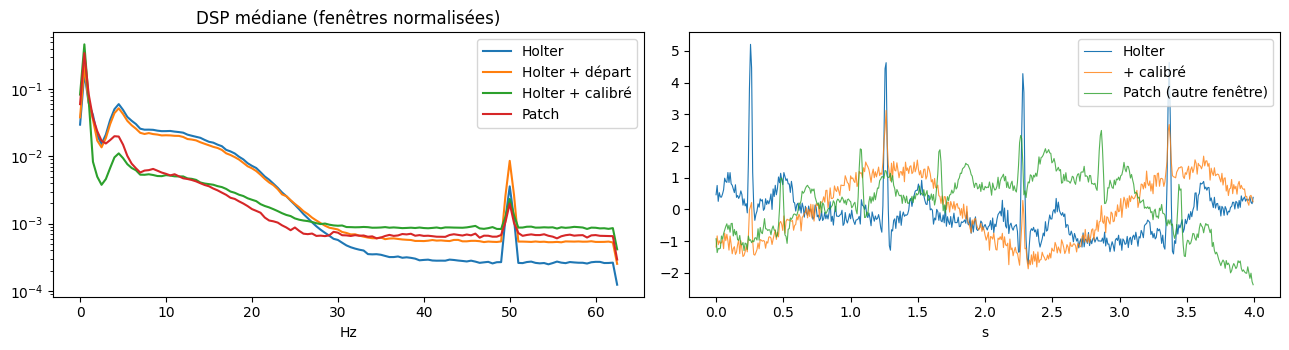

In [9]:
SOS_LP, SOS_HF = butter(2, 0.5, "low", fs=FS, output="sos"), butter(4, 30, "high", fs=FS, output="sos")
def stats_signal(X):
    X = X.astype("float64")
    drift = sosfiltfilt(SOS_LP, X, axis=1).std(1)
    hf = sosfiltfilt(SOS_HF, X, axis=1).std(1)
    Xh = sosfiltfilt(SOS_HP, X, axis=1)
    ramp = np.percentile(Xh, 99.5, axis=1) - np.median(Xh, axis=1)
    f, P = welch(X, fs=FS, nperseg=N, axis=1); df = f[1] - f[0]
    ligne = P[:, (f >= 49.5) & (f <= 50.5)].sum(1) * df
    fond = np.median(P[:, ((f >= 45) & (f < 49)) | ((f > 51) & (f <= 55))], axis=1) * (f[(f >= 49.5) & (f <= 50.5)].size) * df
    raie = np.sqrt(2 * np.clip(ligne - fond, 0, None))
    return {"dérive RMS (mV)": np.median(drift), "bruit HF RMS (mV)": np.median(hf), "amplitude R (mV)": np.median(ramp),
            "raie 50 Hz (mV)": np.median(raie)}

# bruit du code de démarrage (même formules ; générateur passé en argument pour la reproductibilité)
def bruit_depart(X, rng):
    n = len(X); X = X.astype("float32")
    gain = rng.uniform(0.5, 1.0, (n, 1)); f_d = rng.uniform(0.1, 0.5, (n, 1))
    derive = 0.1 * np.sin(2 * np.pi * f_d * temps)
    secteur = 0.02 * np.sin(2 * np.pi * 50 * temps)
    muscle = rng.normal(0.0, 0.03, X.shape)
    return (gain * X + derive + secteur + muscle).astype("float32")

# bruit calibré : gain réduit, dérive plus forte, phases aléatoires, bruit musculaire plus fort
PARAMS_BRUIT = dict(gain=(0.23, 0.48), derive_amp=(0.12, 0.45), derive_f=(0.1, 0.5), secteur_amp=(0.0, 0.015), muscle_sigma=(0.02, 0.09))
def bruit_calibre(X, rng, p=PARAMS_BRUIT):
    n = len(X); X = X.astype("float32")
    u = lambda lo_hi: rng.uniform(lo_hi[0], lo_hi[1], (n, 1))
    derive = u(p["derive_amp"]) * np.sin(2 * np.pi * u(p["derive_f"]) * temps + rng.uniform(0, 2 * np.pi, (n, 1)))
    secteur = u(p["secteur_amp"]) * np.sin(2 * np.pi * 50 * temps + rng.uniform(0, 2 * np.pi, (n, 1)))
    muscle = rng.normal(0.0, 1.0, X.shape) * u(p["muscle_sigma"])
    return (u(p["gain"]) * X + derive + secteur + muscle).astype("float32")

rng_c = np.random.default_rng(1); sub = XA["train"][::7]
tab = pd.DataFrame({"Holter (brut)": stats_signal(sub), "Holter + bruit de départ": stats_signal(bruit_depart(sub, rng_c)),
                    "Holter + bruit calibré": stats_signal(bruit_calibre(sub, rng_c)),
                    "Patch train+val (brut)": stats_signal(np.concatenate([XB["train"], XB["val"]]))}).round(4)
print(tab.to_string())
RES["calibration_bruit"] = tab.to_dict(); RES["params_bruit"] = PARAMS_BRUIT; sauver()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for nom, X in [("Holter", sub), ("Holter + départ", bruit_depart(sub, rng_c)), ("Holter + calibré", bruit_calibre(sub, rng_c)),
               ("Patch", np.concatenate([XB["train"], XB["val"]]))]:
    f, P = welch(normaliser_fenetres(X)[..., 0], fs=FS, nperseg=250, axis=1); ax[0].semilogy(f, np.median(P, 0), label=nom)
ax[0].set_title("DSP médiane (fenêtres normalisées)"); ax[0].set_xlabel("Hz"); ax[0].legend()
i = 3
ax[1].plot(temps[:500], normaliser_fenetres(XA["train"][i:i+1])[0, :500, 0], label="Holter", lw=.8)
ax[1].plot(temps[:500], normaliser_fenetres(bruit_calibre(XA["train"][i:i+1], rng_c))[0, :500, 0], label="+ calibré", lw=.8, alpha=.8)
ax[1].plot(temps[:500], SB["train"][0, :500, 0], label="Patch (autre fenêtre)", lw=.8, alpha=.8); ax[1].legend(); ax[1].set_xlabel("s")
plt.tight_layout(); plt.show()

**Lecture.** Sur les quatre grandeurs, le bruit du code de démarrage laisse le Holter bruité trop proche du Holter (gain 0,5-1 alors que l'amplitude R du patch vaut environ 0,37 fois celle du Holter ; muscle trop faible ; phases identiques pour toutes les fenêtres, ce que l'auto-encodeur peut exploiter). Le bruit calibré rapproche les quatre mesures du patch. Le rapport d'amplitude (≈ 0,37) dépend de la mesure utilisée : une simple hauteur de pic brut donnerait un gain plus élevé (de l'ordre de 0,4 à 0,55, valeur indicative). **Limite connue** : le patch a aussi une *morphologie* différente (autre placement des électrodes, onde T plus grande par rapport au R) qu'un bruit additif ne reproduit pas ; l'auto-encodeur peut nettoyer le bruit, pas changer la morphologie.

## 5. Auto-encodeurs débruiteurs

Entrée : fenêtre de Holter corrompue par le bruit patch, puis normalisée. Cible : la même fenêtre propre, normalisée. Le bruit est **retiré à chaque époque** (nouvelles réalisations), la validation utilise un bruit **fixe** (graine propre) pour comparer les époques et les modèles. Architectures : V1 (auto-encodeur convolutif) et V2 (U-Net à connexions de saut), reprises de votre notebook.

*Corrections apportées par rapport à votre version* : cible de validation = `SA["val"]` (et non `SB["val"]`, fenêtres d'un autre appareil sans lien avec l'entrée) ; apprentissage sur **toutes** les fenêtres d'entraînement (et pas 150) ; bruit à phases aléatoires, régénéré à chaque époque.

In [10]:
class FlotBruite(keras.utils.PyDataset):
    # Génère des lots (entrée bruitée normalisée, cible) avec une NOUVELLE réalisation du bruit à chaque époque.
    def __init__(self, X, fn_bruit, y=None, mode="ae", batch_size=64, par_epoque=None, seed=0):
        super().__init__()
        self.X, self.y, self.fn, self.mode, self.bs = X, y, fn_bruit, mode, batch_size
        self.n = len(X); self.par_epoque = min(par_epoque or self.n, self.n)
        self.rng = np.random.default_rng(seed); self.idx = self.rng.permutation(self.n)[:self.par_epoque]
    def __len__(self): return int(np.ceil(self.par_epoque / self.bs))
    def __getitem__(self, i):
        b = self.idx[i * self.bs:(i + 1) * self.bs]; xb = self.X[b]
        entree = normaliser_fenetres(self.fn(xb, self.rng))
        if self.mode == "ae": return entree, normaliser_fenetres(xb)
        yb = self.y[b]; return entree, yb, np.array([poids[int(c)] for c in yb], dtype="float32")
    def on_epoch_end(self): self.idx = self.rng.permutation(self.n)[:self.par_epoque]

def build_ae_v1():
    i = layers.Input((N, 1))
    x = layers.Conv1D(16, 15, activation="relu", padding="same")(i); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 15, activation="relu", padding="same")(x); z = layers.MaxPooling1D(5)(x)
    x = layers.Conv1D(32, 15, activation="relu", padding="same")(z); x = layers.UpSampling1D(5)(x)
    x = layers.Conv1D(16, 15, activation="relu", padding="same")(x); x = layers.UpSampling1D(2)(x)
    return models.Model(i, layers.Conv1D(1, 15, activation="linear", padding="same")(x))

def build_ae_v2():
    i = layers.Input((N, 1))
    c1 = layers.Conv1D(16, 15, activation="relu", padding="same")(i); p1 = layers.MaxPooling1D(2)(c1)
    c2 = layers.Conv1D(32, 15, activation="relu", padding="same")(p1); p2 = layers.MaxPooling1D(5)(c2)
    z = layers.Conv1D(64, 15, activation="relu", padding="same")(p2)
    u2 = layers.Conv1D(32, 15, activation="relu", padding="same")(layers.Concatenate()([layers.UpSampling1D(5)(z), c2]))
    u1 = layers.Conv1D(16, 15, activation="relu", padding="same")(layers.Concatenate()([layers.UpSampling1D(2)(u2), c1]))
    return models.Model(i, layers.Conv1D(1, 15, activation="linear", padding="same")(u1))

# validation à bruit FIXE (calibré) : même entrée bruitée pour tous les AE -> comparaison équitable
Xv_noisy = normaliser_fenetres(bruit_calibre(XA["val"], np.random.default_rng(123)))
Xv_noisy_depart = normaliser_fenetres(bruit_depart(XA["val"], np.random.default_rng(123)))

def snr_db(ref, est):
    ref, est = ref[..., 0], est[..., 0]
    return float(np.median(10 * np.log10((ref ** 2).sum(1) / (((est - ref) ** 2).sum(1) + 1e-12))))

EPOQUES_AE, PAR_EPOQUE_AE = (1, 300) if RAPIDE else (10, 4200)
AE, AE_INFO = {}, []
for nom, build, fn in [("AE_V1 (conv)", build_ae_v1, bruit_calibre), ("AE_V2 (U-Net)", build_ae_v2, bruit_calibre),
                       ("AE_V2 (U-Net), bruit de départ", build_ae_v2, bruit_depart)]:
    fixer_graines(); t0 = time.time()
    ae = build(); ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    gen = FlotBruite(XA["train"], fn, mode="ae", batch_size=64, par_epoque=PAR_EPOQUE_AE, seed=SEED)
    h = ae.fit(gen, validation_data=(Xv_noisy if fn is bruit_calibre else Xv_noisy_depart, SA["val"]), epochs=EPOQUES_AE, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    AE[nom] = ae; ae.save(f"modeles/{nom.split(' ')[0]}_{'depart' if fn is bruit_depart else 'calibre'}.keras")
    # métriques sur le bruit CALIBRÉ fixe (proxy du patch réel), quel que soit le bruit d'entraînement
    sortie = ae.predict(Xv_noisy, batch_size=128, verbose=0)
    info = {"modèle": nom, "params": ae.count_params(), "MSE val (bruit calibré)": float(np.mean((sortie - SA["val"]) ** 2)),
            "MSE avant débruitage": float(np.mean((Xv_noisy - SA["val"]) ** 2)),
            "SNR avant (dB)": round(snr_db(SA["val"], Xv_noisy), 2), "SNR après (dB)": round(snr_db(SA["val"], sortie), 2),
            "époques": len(h.history["loss"]), "durée (s)": round(time.time() - t0)}
    AE_INFO.append(info); print(info)
    journaliser(2, "ae::" + nom, {"bruit": "départ" if fn is bruit_depart else "calibré", "epoques": EPOQUES_AE}, {k: v for k, v in info.items() if k != "modèle"})
AE_DF = pd.DataFrame(AE_INFO); print(); print(AE_DF.round(4).to_string(index=False))
RES["ae"] = AE_DF.to_dict("records"); sauver()

E0000 00:00:1792140514.024425     101 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


{'modèle': 'AE_V1 (conv)', 'params': 31297, 'MSE val (bruit calibré)': 0.35227417945861816, 'MSE avant débruitage': 1.1032484769821167, 'SNR avant (dB)': -0.35, 'SNR après (dB)': 5.09, 'époques': 10, 'durée (s)': 53}


{'modèle': 'AE_V2 (U-Net)', 'params': 96641, 'MSE val (bruit calibré)': 0.3185725510120392, 'MSE avant débruitage': 1.1032484769821167, 'SNR avant (dB)': -0.35, 'SNR après (dB)': 5.61, 'époques': 10, 'durée (s)': 203}


{'modèle': 'AE_V2 (U-Net), bruit de départ', 'params': 96641, 'MSE val (bruit calibré)': 0.9148087501525879, 'MSE avant débruitage': 1.1032484769821167, 'SNR avant (dB)': -0.35, 'SNR après (dB)': 0.56, 'époques': 10, 'durée (s)': 209}

                        modèle  params  MSE val (bruit calibré)  MSE avant débruitage  SNR avant (dB)  SNR après (dB)  époques  durée (s)
                  AE_V1 (conv)   31297                   0.3523                1.1032           -0.35            5.09       10         53
                 AE_V2 (U-Net)   96641                   0.3186                1.1032           -0.35            5.61       10        203
AE_V2 (U-Net), bruit de départ   96641                   0.9148                1.1032           -0.35            0.56       10        209


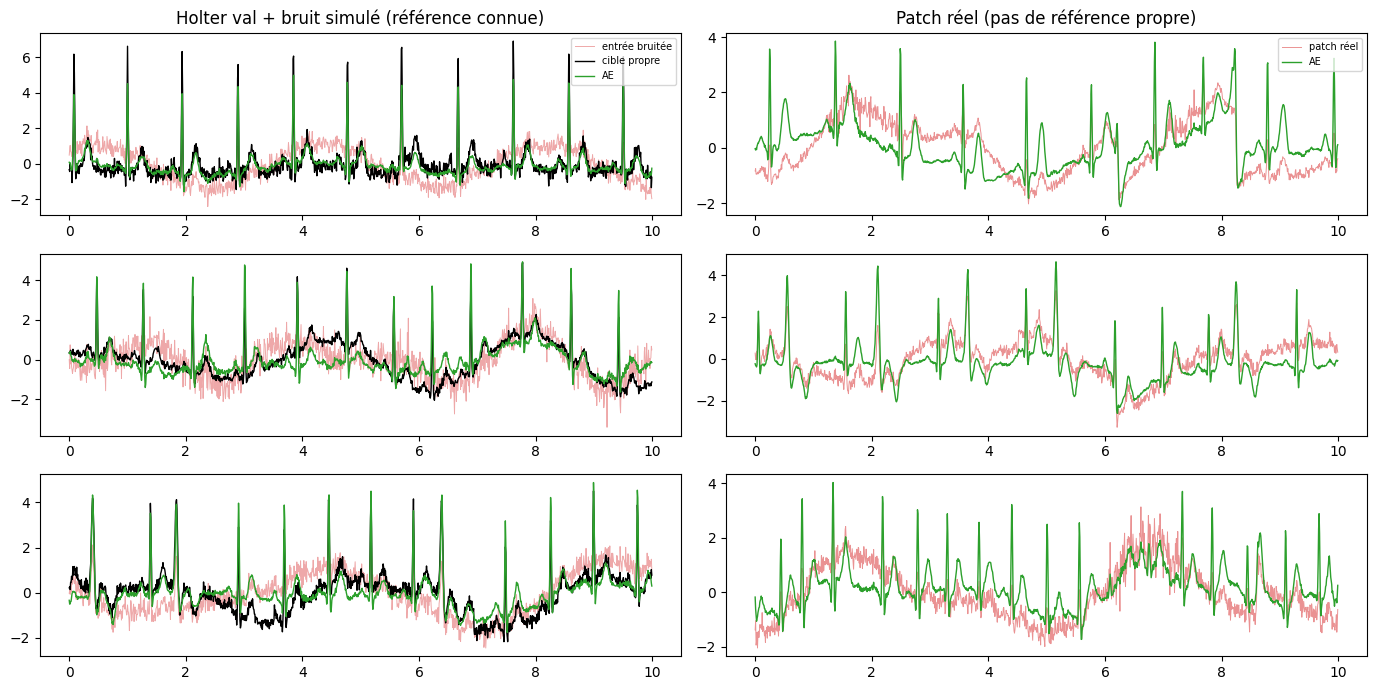

In [11]:
# Visualisation : (a) Holter val + bruit calibré, (b) vraies fenêtres du patch (validation)
ae_vis = AE["AE_V2 (U-Net)"]
sortie_v = ae_vis.predict(Xv_noisy[:3], verbose=0); IB = [0, len(SB["val"]) // 3, 2 * len(SB["val"]) // 3]; sortie_b = ae_vis.predict(SB["val"][IB], verbose=0)
fig, ax = plt.subplots(3, 2, figsize=(14, 7))
for r in range(3):
    ax[r, 0].plot(temps, Xv_noisy[r, :, 0], c="tab:red", alpha=.4, lw=.7, label="entrée bruitée")
    ax[r, 0].plot(temps, SA["val"][r, :, 0], c="k", lw=1, label="cible propre"); ax[r, 0].plot(temps, sortie_v[r, :, 0], c="tab:green", lw=1, label="AE")
    ax[r, 1].plot(temps, SB["val"][IB[r], :, 0], c="tab:red", alpha=.5, lw=.7, label="patch réel"); ax[r, 1].plot(temps, sortie_b[r, :, 0], c="tab:green", lw=1, label="AE")
ax[0, 0].set_title("Holter val + bruit simulé (référence connue)"); ax[0, 1].set_title("Patch réel (pas de référence propre)")
ax[0, 0].legend(loc="upper right", fontsize=7); ax[0, 1].legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.show()

## 6. Effet du débruitage sur la classification du patch (validation)

Même CNN (appris sur le Holter) ; seule l'entrée change : fenêtre du patch normalisée, avec ou sans passage par l'auto-encodeur (la sortie est renormalisée). On ajoute deux contrôles : le Holter de validation bruité par le bruit calibré (vérité connue), et — à titre **exploratoire** — un CNN entraîné directement sur du Holter bruité (augmentation de données) pour comparer « débruiter avant » et « apprendre à tolérer le bruit ».

**Précision statistique.** La validation du patch compte 150 fenêtres issues de 6 patients (classes : 67, 6, 43, 9, 25) : les intervalles de confiance (bootstrap sur les patients) sont larges, les différences de quelques points sont à lire avec prudence.

In [12]:
def classer(model, S): return model.predict(S, batch_size=128, verbose=0).argmax(1)
def debruiter(ae, S): return normaliser_fenetres(ae.predict(S, batch_size=128, verbose=0)[..., 0])

# CNN exploratoire entraîné sur Holter bruité (augmentation)
fixer_graines()
prof, k, agg, dil = CONFIGS[NOM_CNN]
cnn_aug = construire_cnn(prof, k, agg, dil)
gen_aug = FlotBruite(XA["train"], bruit_calibre, y=A["classe_train"], mode="cls", batch_size=64, seed=SEED)
entrainer(cnn_aug, gen_aug, (SA["val"], A["classe_val"]), EPOQUES_CNN)

rows = []
def ajouter(nom, model, S, y, pat):
    p = classer(model, S); m = metriques(y, p); lo, hi = ic_bootstrap(y, p, pat, B_=20 if RAPIDE else 500)
    rows.append({"condition": nom, "F1 macro": round(m["f1_macro"], 3), "IC95 % patients": f"[{lo:.2f} ; {hi:.2f}]",
                 "sensibilité alerte": round(m["sensibilite_alerte"], 3), "fausses alertes": round(m["fausses_alertes"], 3),
                 "F1 par classe": m["f1_classes"]})
    return m

ajouter("Patch val : CNN, sans débruitage", cnn, SB["val"], B["classe_val"], B["patient_val"])
for nom, ae in AE.items():
    ajouter(f"Patch val : CNN après {nom}", cnn, debruiter(ae, SB["val"]), B["classe_val"], B["patient_val"])
ajouter("Patch val : CNN entraîné sur Holter bruité (exploratoire)", cnn_aug, SB["val"], B["classe_val"], B["patient_val"])
ajouter("Holter val + bruit calibré : CNN, sans débruitage", cnn, Xv_noisy, A["classe_val"], A["patient_val"])
for nom, ae in AE.items():
    ajouter(f"Holter val + bruit calibré : CNN après {nom}", cnn, debruiter(ae, Xv_noisy), A["classe_val"], A["patient_val"])
ajouter("Holter val propre : CNN (référence)", cnn, SA["val"], A["classe_val"], A["patient_val"])
DEB_DF = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80)
print(DEB_DF.drop(columns="F1 par classe").to_string(index=False))
RES["debruitage_val"] = DEB_DF.to_dict("records")
journaliser(2, "debruitage_patch_val", {"cnn": NOM_CNN}, {r["condition"]: r["F1 macro"] for r in rows}, "avec/sans débruitage"); sauver()

                                                            condition  F1 macro IC95 % patients  sensibilité alerte  fausses alertes
                                     Patch val : CNN, sans débruitage     0.571   [0.45 ; 0.68]               1.000            0.731
                                   Patch val : CNN après AE_V1 (conv)     0.903   [0.78 ; 1.00]               1.000            0.119
                                  Patch val : CNN après AE_V2 (U-Net)     0.918   [0.80 ; 1.00]               1.000            0.090
                 Patch val : CNN après AE_V2 (U-Net), bruit de départ     0.672   [0.52 ; 0.75]               1.000            0.642
            Patch val : CNN entraîné sur Holter bruité (exploratoire)     0.923   [0.73 ; 0.97]               1.000            0.134
                    Holter val + bruit calibré : CNN, sans débruitage     0.500   [0.44 ; 0.55]               0.989            0.716
                  Holter val + bruit calibré : CNN après AE_V1 (conv)

## 7. Choix finaux, contraintes d'embarquement, évaluation finale

**Choix de l'auto-encodeur** (règle fixée à l'avance) : plus faible MSE de validation sur le Holter à bruit calibré parmi les AE entraînés avec le bruit calibré.

**Contrainte d'embarquement.** Tous les modèles candidats respectent largement ≤ 2 Mo et ≤ 100 ms ; la contrainte n'a pas servi à choisir le CNN (voir la règle de sélection en section 3). Les mesures ci-dessous sont faites sur un cœur de serveur et ne remplacent pas une mesure sur le matériel du patch.

In [13]:
cand_ae = AE_DF[AE_DF["modèle"].isin(["AE_V1 (conv)", "AE_V2 (U-Net)"])].sort_values("MSE val (bruit calibré)")
NOM_AE = cand_ae.iloc[0]["modèle"]; ae_ret = AE[NOM_AE]
print("AE retenu :", NOM_AE); RES["ae_retenu"] = NOM_AE

# --- taille et latence (CPU de cette machine, 1 fenêtre à la fois) ---
def latence_keras(model, n=100):
    x = tf.constant(np.random.default_rng(0).normal(size=(1, N, 1)).astype("float32"))
    f = tf.function(lambda z: model(z, training=False)); f(x); f(x)
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); f(x).numpy(); t.append(time.perf_counter() - t0)
    return 1000 * float(np.median(t))

import contextlib, io, logging
tf.get_logger().setLevel(logging.ERROR)
def tflite_info(model, quant=False, n=100):
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(model)
        if quant: conv.optimizations = [tf.lite.Optimize.DEFAULT]
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            buf = conv.convert()
        it = tf.lite.Interpreter(model_content=buf, num_threads=1); it.allocate_tensors()
        x = np.random.default_rng(0).normal(size=(1, N, 1)).astype("float32")
        i, o = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
        t = []
        for _ in range(n):
            it.set_tensor(i, x); t0 = time.perf_counter(); it.invoke(); t.append(time.perf_counter() - t0)
        return len(buf) / 1e6, 1000 * float(np.median(t))
    except Exception as e:
        return None, str(e)[:80]

emb = []
for nom, mdl in [(f"CNN {NOM_CNN}", cnn), (NOM_AE, ae_ret)]:
    s32, l32 = tflite_info(mdl); sq, lq = tflite_info(mdl, quant=True)
    emb.append({"modèle": nom, "params": mdl.count_params(), "Keras (ms/fenêtre)": round(latence_keras(mdl), 2),
                "TFLite float32 (Mo)": None if s32 is None else round(s32, 3), "TFLite float32 (ms)": l32 if s32 is None else round(l32, 2),
                "TFLite quantifié (Mo)": None if sq is None else round(sq, 3), "TFLite quantifié (ms)": lq if sq is None else round(lq, 2)})
EMB_DF = pd.DataFrame(emb); print(EMB_DF.to_string(index=False))
tot_mo = sum(x for x in EMB_DF["TFLite float32 (Mo)"] if isinstance(x, float))
print(f"Pipeline AE + CNN : {tot_mo:.3f} Mo en float32 (cible <= 2 Mo) ; latence TFLite cumulée "
      f"{sum(x for x in EMB_DF['TFLite float32 (ms)'] if isinstance(x, float)):.1f} ms (cible <= 100 ms, mesurée sur un coeur de serveur, pas sur le patch)")
RES["embarque"] = EMB_DF.to_dict("records"); sauver()

AE retenu : AE_V2 (U-Net)


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


E0000 00:00:1792141078.805164    2437 node_def_util.cc:682] NodeDef mentions attribute Truncate which is not in the op definition: Op<name=Identity; signature=input:T -> output:T; attr=T:type> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node unnamed}}


       modèle  params  Keras (ms/fenêtre)  TFLite float32 (Mo)  TFLite float32 (ms)  TFLite quantifié (Mo)  TFLite quantifié (ms)
CNN d4_k7_dil   37077                0.59                0.162                 0.20                  0.056                   0.09
AE_V2 (U-Net)   96641                0.95                0.400                 0.94                  0.114                   0.38
Pipeline AE + CNN : 0.562 Mo en float32 (cible <= 2 Mo) ; latence TFLite cumulée 1.1 ms (cible <= 100 ms, mesurée sur un coeur de serveur, pas sur le patch)


### Évaluation finale sur le test (une seule fois)
Modèles **figés** : CNN retenu, AE retenu. Aucun réglage n'est modifié après cette cellule. Le CNN exploratoire entraîné sur Holter bruité n'est pas évalué sur le test (il n'est pas le modèle retenu).

In [14]:
def evaluation_finale(split):
    resultat = {}
    SAs = SA[split]; SBs = SB[split]
    pA = classer(cnn, SAs); mA = metriques(A["classe_" + split], pA); mA["ic95"] = ic_bootstrap(A["classe_" + split], pA, A["patient_" + split], B_=20 if RAPIDE else 1000)
    pB0 = classer(cnn, SBs); mB0 = metriques(B["classe_" + split], pB0); mB0["ic95"] = ic_bootstrap(B["classe_" + split], pB0, B["patient_" + split], B_=20 if RAPIDE else 1000)
    pB1 = classer(cnn, debruiter(ae_ret, SBs)); mB1 = metriques(B["classe_" + split], pB1); mB1["ic95"] = ic_bootstrap(B["classe_" + split], pB1, B["patient_" + split], B_=20 if RAPIDE else 1000)
    return {"holter": mA, "patch_sans_debruitage": mB0, "patch_avec_debruitage": mB1,
            "confusion_holter": confusion_matrix(A["classe_" + split], pA, labels=range(5)).tolist(),
            "confusion_patch_sans": confusion_matrix(B["classe_" + split], pB0, labels=range(5)).tolist(),
            "confusion_patch_avec": confusion_matrix(B["classe_" + split], pB1, labels=range(5)).tolist()}

SPLIT_FINAL = "val" if RAPIDE else "test"     # en mode fumée on ne touche PAS au test
FIN = evaluation_finale(SPLIT_FINAL)
cibles = {"holter": 0.97, "patch_sans_debruitage": 0.85, "patch_avec_debruitage": 0.85}
tab_fin = pd.DataFrame([{"condition": k, "F1 macro": round(v["f1_macro"], 3), "IC95 % patients": f"[{v['ic95'][0]:.2f} ; {v['ic95'][1]:.2f}]",
                         "cible": cibles[k], "écart": round(v["f1_macro"] - cibles[k], 3), "sensibilité alerte": round(v["sensibilite_alerte"], 3),
                         "fausses alertes": round(v["fausses_alertes"], 3)} for k, v in FIN.items() if k in cibles])
print("Évaluation sur :", SPLIT_FINAL); print(tab_fin.to_string(index=False))
print("\nF1 par classe :"); print(pd.DataFrame({k: FIN[k]["f1_classes"] for k in cibles}, index=NOMS).T.to_string())
RES["final"] = {"split": SPLIT_FINAL, **FIN}
journaliser(2, "evaluation_finale", {"cnn": NOM_CNN, "ae": NOM_AE, "split": SPLIT_FINAL}, {k: FIN[k]["f1_macro"] for k in cibles}, "une seule évaluation sur le test")
sauver()

Évaluation sur : test
            condition  F1 macro IC95 % patients  cible  écart  sensibilité alerte  fausses alertes
               holter     0.994   [0.99 ; 1.00]   0.97  0.024               0.998            0.009
patch_sans_debruitage     0.519   [0.46 ; 0.57]   0.85 -0.331               1.000            0.753
patch_avec_debruitage     0.901   [0.80 ; 0.94]   0.85  0.051               0.960            0.077

F1 par classe :
                       sinusal     FA    ESV  tachy sin.  bloc AV
holter                   0.994  0.988  0.995       1.000    0.995
patch_sans_debruitage    0.397  0.623  0.813       0.651    0.112
patch_avec_debruitage    0.944  0.877  0.972       0.948    0.762


## Journal d'expériences

In [15]:
J = pd.read_csv(JOURNAL); print(len(J), "essais journalisés dans", JOURNAL); print(J[["horodatage", "jalon", "essai", "remarque"]].to_string(index=False))

15 essais journalisés dans journal_experiences.csv
         horodatage  jalon                              essai                         remarque
2026-10-16 08:32:59      2                   mlp_descripteurs         comparateur réimplémenté
2026-10-16 08:34:13      2                          d4_k7_gap                              NaN
2026-10-16 08:35:05      2                          d2_k7_gap                              NaN
2026-10-16 08:36:35      2                          d3_k7_gap                              NaN
2026-10-16 08:38:20      2                          d5_k7_gap                              NaN
2026-10-16 08:39:54      2                          d4_k3_gap                              NaN
2026-10-16 08:43:22      2                         d4_k15_gap                              NaN
2026-10-16 08:45:06      2                         d4_k7_flat                              NaN
2026-10-16 08:46:46      2                          d4_k7_dil                              NaN

# Page de décisions : Jalon 2 (CNN 1D et auto-encodeurs)

Tous les réglages ont été faits sur la validation. Le test n'a servi qu'une fois, pour les modèles figés (section 7). Les chiffres ci-dessous sont ceux de l'exécution de ce notebook (graine fixée ; Python 3.12.3, numpy 2.4.4, scipy 1.17.1, scikit-learn 1.8.0, TensorFlow 2.21.0, pandas 3.0.2 ; exécution sur 1 cœur CPU, environ 25 min).

## 1. Tableau des résultats

**Ablations du CNN (validation, une graine).** Les écarts de 0,005 à 0,01 ne sont pas conclusifs.

| Essai | Params | Champ réceptif | F1 Holter val | F1 patch val |
|---|---|---|---|---|
| MLP sur descripteurs RR (comparateur) | 3 141 | n.a. | 0,973 | 0,681 |
| 2 blocs, k=7, moyenne globale | 4 101 | 22 éch. (0,18 s) | 0,648 | 0,353 |
| 3 blocs, k=7, moyenne globale | 15 173 | 50 éch. (0,40 s) | 0,933 | 0,511 |
| 4 blocs, k=3, moyenne globale | 16 533 | 46 éch. (0,37 s) | 0,894 | 0,494 |
| 4 blocs, k=7, moyenne globale (référence) | 37 077 | 106 éch. (0,85 s) | 0,969 | 0,395 |
| 4 blocs, k=7, aplatissement | 61 717 | 106 éch. (0,85 s) | 0,979 | 0,684 |
| 4 blocs, k=7, référence + passe-haut 0,5 Hz | 37 077 | 106 éch. (0,85 s) | 0,987 | 0,689 |
| 4 blocs, k=15, moyenne globale | 78 165 | 226 éch. (1,81 s) | 0,992 | 0,541 |
| 5 blocs, k=7, moyenne globale | 66 069 | 218 éch. (1,74 s) | 0,995 | 0,694 |
| **4 blocs, k=7, dilatations 1-2-4-8, moyenne globale (retenu)** | **37 077** | **526 éch. (4,21 s)** | **0,991** | **0,571** |

**Effet du débruitage sur le patch (validation, CNN retenu inchangé).**

| Entrée du CNN | F1 macro | IC95 % (patients) | Fausses alertes |
|---|---|---|---|
| Patch brut | 0,571 | [0,45 ; 0,68] | 0,731 |
| Patch + AE_V1 (conv) | 0,903 | [0,78 ; 1,00] | 0,119 |
| Patch + AE_V2 (U-Net) (retenu) | 0,918 | [0,80 ; 1,00] | 0,090 |
| Patch + AE_V2 entraîné avec le bruit de départ | 0,672 | [0,52 ; 0,75] | 0,642 |

**Évaluation finale sur le test (modèles figés, une seule fois).**

| Condition | F1 macro | IC95 % (patients) | Cible | Écart | Sensibilité alerte | Fausses alertes |
|---|---|---|---|---|---|---|
| Holter | 0,994 | [0,99 ; 1,00] | 0,97 | +0,024 | 0,998 | 0,009 |
| Patch sans débruitage | 0,519 | [0,46 ; 0,57] | 0,85 | −0,331 | 1,000 | 0,753 |
| Patch avec débruitage (AE_V2) | 0,901 | [0,80 ; 0,94] | 0,85 | +0,051 | 0,960 | 0,077 |

F1 par classe sur le test (sinusal, FA, ESV, tachy sin., bloc AV) : Holter 0,994 / 0,988 / 0,995 / 1,000 / 0,995 ; patch sans débruitage 0,397 / 0,623 / 0,813 / 0,651 / 0,112 ; patch avec débruitage 0,944 / 0,877 / 0,972 / 0,948 / 0,762.

**Embarquement (TFLite float32, 1 cœur de serveur).** CNN : 0,162 Mo, 0,20 ms. AE : 0,400 Mo, 0,94 ms. Pipeline AE + CNN : **0,562 Mo (cible ≤ 2 Mo) et 1,1 ms par fenêtre (cible ≤ 100 ms)**. Mesures faites sur un serveur, pas sur le matériel du patch.

## 2. Choix retenus et justifications

**Normalisation par fenêtre (z-score).** Elle retire le gain et le décalage propres à chaque enregistrement. C'est indispensable ici, car l'amplitude des pics R du patch vaut environ 0,37 fois celle du Holter (mesure de la section 4) : sans normalisation, un CNN appris sur le Holter verrait des signaux d'échelle très différente. Limite observée : quand les QRS sont petits, le z-score est dominé par la dérive de ligne de base. Un passe-haut à 0,5 Hz avant le z-score, testé sur l'architecture de référence, fait passer la F1 de 0,969 à 0,987 sur le Holter et de 0,395 à 0,689 sur le patch en validation. Je ne l'ai pas intégré au pipeline retenu, car le choix du CNN suit une règle fixée à l'avance sur le Holter ; c'est la première piste à tester ensuite.

**Architecture : 4 blocs, noyau 7, dilatations 1-2-4-8, moyenne globale (37 077 paramètres).** Règle fixée à l'avance : meilleure F1 macro sur la validation Holter, et à ±0,005 près le plus petit modèle. Le modèle à 5 blocs a la meilleure F1 (0,995), mais l'écart avec le modèle à dilatations (0,004) est dans la tolérance, et il coûte 78 % de paramètres en plus. Les dilatations donnent un champ réceptif de 4,21 s sans paramètre supplémentaire, ce qui couvre plusieurs intervalles RR (nécessaires pour la FA et le bloc AV, voir section 3). La moyenne globale est légère et invariante par décalage ; elle perd l'ordre temporel, ce que compense le grand champ réceptif. L'aplatissement conserve la position mais coûte 24 640 paramètres de plus à champ réceptif égal, pour un gain (0,979 contre 0,969) dans le bruit d'une graine.

**Contrainte d'embarquement.** Elle ne départage pas les candidats : le plus gros CNN testé (78 165 paramètres) pèse environ 0,31 Mo, très en dessous de 2 Mo. Le pipeline retenu pèse 0,56 Mo et tourne en 1,1 ms, avec une marge d'un facteur 3 en taille et de 90 en latence sur les cibles.

**Bruit « de type patch » calibré.** Les quatre grandeurs mesurées (dérive, bruit haute fréquence, amplitude R, raie à 50 Hz) sont rapprochées de celles du patch (train + val seulement, jamais le test). Le bruit de départ laisse le Holter trop proche de lui-même (gain trop élevé, phases identiques pour toutes les fenêtres que l'auto-encodeur peut exploiter) : un AE entraîné avec lui n'améliore presque rien (SNR 0,56 dB ; F1 patch val 0,672). Avec le bruit calibré, le SNR passe de −0,35 à 5,61 dB.

**Auto-encodeur : AE_V2 (U-Net, 96 641 paramètres).** Règle fixée à l'avance : plus faible MSE de validation Holter à bruit calibré (0,319 contre 0,352 pour l'AE_V1).

## 3. Vérifications théoriques

**Champ réceptif de 4 × (conv noyau 7 + max-pooling 2).** À la main (section 2) : r = 7, 8, 20, 22, 46, 50, 98, **106 échantillons**, soit 106 / 125 = **0,85 s**. Le calcul par la formule et par le gradient donne 106 dans les deux cas.

**Couvre-t-il un battement ?** Oui : 0,85 s contient le QRS (environ 0,1 s) et l'onde P à T. **Un intervalle RR à 70 bpm** (0,857 s, 107 échantillons) : tout juste non (106 < 107). **Deux intervalles RR** (1,71 s, 214 échantillons) : non.

**Conséquences.** La fibrillation atriale (RR irréguliers) et le bloc AV du 2e degré (pause, onde P non conduite) sont des propriétés de plusieurs battements : un réseau qui ne compare pas deux intervalles ne peut pas les lire directement.

**Remèdes.** (i) Profondeur : 5 blocs donnent 218 échantillons (couvre 2 RR), 6 blocs 442. (ii) Dilatation : 526 échantillons (4,21 s) sans paramètre supplémentaire, solution retenue. (iii) Agrégation globale : la moyenne perd l'ordre temporel, d'où l'intérêt de la combiner avec un grand champ réceptif ; un maximum global en plus est une piste non testée.

**Ce que disent les mesures.** Les modèles dont le champ réceptif est très inférieur à 214 échantillons sont nettement moins bons sur le Holter (0,65 à 0,93) ; les trois essais au-delà de 214 échantillons dépassent 0,99. C'est une tendance, pas une loi : à champ réceptif égal (106 éch.), l'aplatissement et le passe-haut font mieux que la référence, et au-delà de 214 éch. plus de champ n'apporte rien de plus.

## 4. Écarts aux cibles du cahier des charges

Ces cibles décrivent le système final, elles ne sont pas exigées à ce stade.

- **Holter (cible 0,97) :** atteinte (0,994). Le CNN dépasse le MLP surtout sur la FA (0,992 contre 0,925 en validation), conformément à l'analyse du champ réceptif. Le MLP reste légèrement meilleur sur les ESV (0,986 contre 0,977).
- **Patch sans débruitage (cible 0,85) :** très en dessous (0,519), avec 75 % de fausses alertes : un CNN appris sur le Holter ne transfère pas. Le MLP sur descripteurs RR était plus robuste sur le patch brut (0,681 contre 0,571 en validation) ; je suppose que les intervalles RR dépendent moins de l'amplitude et de la morphologie, mais je ne l'ai pas testé.
- **Patch avec débruitage (cible 0,85) :** atteinte sur l'estimation (0,901), mais **la borne basse de l'IC (0,80) est sous la cible** : on ne peut pas l'affirmer avec certitude. Le test patch contient 42 patients, ce qui donne un IC plus étroit qu'en validation (6 patients), mais il reste large.
- **Compromis du débruitage :** les fausses alertes passent de 75 % à 7,7 %, mais la sensibilité d'alerte passe de 1,000 à 0,960 : environ 4 % des fenêtres d'arythmie ne déclenchent plus d'alerte. À examiner pour la note de décision.
- **Bloc AV sur le patch :** reste la classe la plus faible (F1 0,762) : rappel de 1,0 mais précision de 0,62 (15 sinusales et 24 vraies fenêtres prédites en bloc AV, d'après la matrice de confusion). La classe ne compte que 24 fenêtres au test (environ un patient), donc ce chiffre est très incertain.
- **Embarquement :** cibles tenues largement (0,56 Mo, 1,1 ms), mais mesurées sur serveur.

## 5. Limites et suites

- Une seule graine par essai : les classements proches ne sont pas fiables.
- La validation du patch ne compte que 6 patients ; elle a servi à comparer les conditions, pas à régler finement.
- Un bruit additif ne reproduit pas la morphologie différente du patch (autre placement des électrodes) : l'AE nettoie le bruit, il ne change pas la forme des ondes. C'est probablement la source de l'écart restant.
- Un CNN entraîné directement sur du Holter bruité (exploratoire) atteint 0,923 sur le patch en validation (IC [0,73 ; 0,97]) ; il n'est pas évalué sur le test, car il n'est pas le modèle retenu.
- Pistes pour le jalon suivant : passe-haut avant le z-score, maximum global en plus de la moyenne, plusieurs graines avec validation croisée par patient, réglage fin avec les 12 patients annotés du patch.
